# PhiUSIIL: Individual Exploratory Data Analysis

**Research question:** Which URL and webpage features are shared by both phishing and legitimate websites, potentially making them harder to distinguish?

This notebook explores only the primary PhiUSIIL CSV. Each row represents a URL and its webpage. The labels are **0 = phishing** and **1 = legitimate**, as stated in the project README and [UCI dataset documentation](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset). The data describes technical characteristics, not participants' recognition accuracy. No URLs are visited during this analysis.

In [ ]:
from pathlib import Path
from urllib.parse import urlsplit
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(12)
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Support running from the notebooks folder or repository root :)
data_path = Path("../datasets/PhiUSIIL_Phishing_URL_Dataset.csv")
if not data_path.exists():
    data_path = Path("datasets/PhiUSIIL_Phishing_URL_Dataset.csv")
df = pl.read_csv(data_path)
class_names = ["Phishing (0)", "Legitimate (1)"]
colors = ["#c65a46", "#3579a8"]

## A. Dataset profiling

In [2]:
print("Shape:", df.shape)
df.glimpse()
display(df.head(3).select("URL", "URLLength", "Domain", "IsHTTPS", "label"))

Shape: (235795, 56)
Rows: 235795
Columns: 56
$ FILENAME                   <str> '521848.txt', '31372.txt', '597387.txt', '554095.txt', '151578.txt', '23107.txt', '23034.txt', '696732.txt', '739255.txt', '14486.txt'
$ URL                        <str> 'https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org', 'https://www.globalreporting.org', 'https://www.saffronart.com', 'https://www.nerdscandy.com', 'https://www.hyderabadonline.in', 'https://www.aap.org'
$ URLLength                  <i64> 31, 23, 29, 26, 33, 30, 25, 25, 29, 18
$ Domain                     <str> 'www.southbankmosaics.com', 'www.uni-mainz.de', 'www.voicefmradio.co.uk', 'www.sfnmjournal.com', 'www.rewildingargentina.org', 'www.globalreporting.org', 'www.saffronart.com', 'www.nerdscandy.com', 'www.hyderabadonline.in', 'www.aap.org'
$ DomainLength               <i64> 24, 16, 22, 19, 26, 23, 18, 18, 22, 11
$ IsDomainI

URL,URLLength,Domain,IsHTTPS,label
str,i64,str,i64,i64
"""https://www.southbankmosaics.c…",31,"""www.southbankmosaics.com""",1,1
"""https://www.uni-mainz.de""",23,"""www.uni-mainz.de""",1,1
"""https://www.voicefmradio.co.uk""",29,"""www.voicefmradio.co.uk""",1,1


There are **235,795 rows and 56 columns**: five text columns, 41 integer columns, and ten floating-point columns. `FILENAME` is an identifier, and `label` is the classification. Binary indicators load as integers; ratios and match scores load as floats. The CSV spellings, including `NoOfDegitsInURL` and `SpacialCharRatioInURL`, are kept.

In [3]:
nulls = df.null_count()
display(nulls.transpose(include_header=True, header_name="column", column_names=["null_count"]))
summary = df.describe().with_columns(pl.col(pl.Float64).round(3))
profile = summary.drop("statistic").transpose(
    include_header=True, header_name="column", column_names=summary["statistic"].to_list()
)
display(profile.select("column", "count", "null_count", "min", "max"))
display(profile.select("column", "mean", "std", "25%", "50%", "75%"))

column,null_count
str,u32
"""FILENAME""",0
"""URL""",0
"""URLLength""",0
"""Domain""",0
"""DomainLength""",0
"""IsDomainIP""",0
"""TLD""",0
"""URLSimilarityIndex""",0
"""CharContinuationRate""",0


column,count,null_count,min,max
str,str,str,str,str
"""FILENAME""","""235795""","""0""","""100000.txt""","""oph15000.txt"""
"""URL""","""235795""","""0""","""http://0-lxshop7.45654335.xyz/…","""https://zzqqw1.godaddysites.co…"
"""URLLength""","""235795.0""","""0.0""","""13.0""","""6097.0"""
"""Domain""","""235795""","""0""","""0-lxshop7.45654335.xyz""","""zzzzzzzzzzzzzzz.hyperphp.com"""
"""DomainLength""","""235795.0""","""0.0""","""4.0""","""110.0"""
"""IsDomainIP""","""235795.0""","""0.0""","""0.0""","""1.0"""
"""TLD""","""235795""","""0""","""100""","""zw"""
"""URLSimilarityIndex""","""235795.0""","""0.0""","""0.156""","""100.0"""
"""CharContinuationRate""","""235795.0""","""0.0""","""0.0""","""1.0"""


column,mean,std,25%,50%,75%
str,str,str,str,str,str
"""FILENAME""",null,null,null,null,null
"""URL""",null,null,null,null,null
"""URLLength""","""34.573""","""41.314""","""23.0""","""27.0""","""34.0"""
"""Domain""",null,null,null,null,null
"""DomainLength""","""21.47""","""9.151""","""16.0""","""20.0""","""24.0"""
"""IsDomainIP""","""0.003""","""0.052""","""0.0""","""0.0""","""0.0"""
"""TLD""",null,null,null,null,null
"""URLSimilarityIndex""","""78.431""","""28.976""","""57.025""","""100.0""","""100.0"""
"""CharContinuationRate""","""0.846""","""0.217""","""0.68""","""1.0""","""1.0"""


All 56 columns have zero null values. The summary shows long right tails: `URLLength` reaches 6,097 and `LineOfCode` reaches 442,666. These maxima deserve inspection but are not automatically impossible. Binary columns have values between 0 and 1.

label,len,percent
i64,u32,f64
0,100945,42.810492
1,134850,57.189508


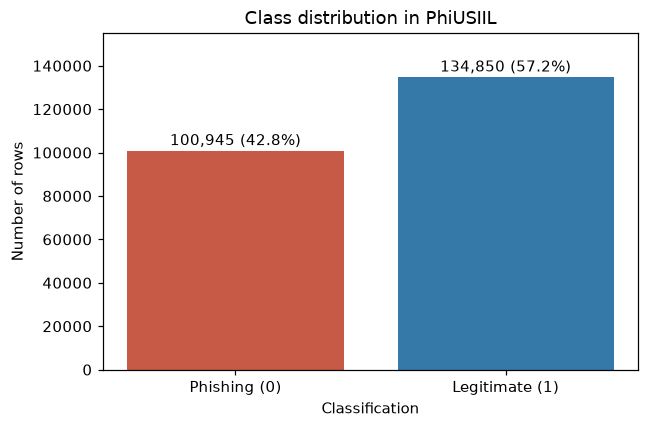

In [4]:
class_counts = df.group_by("label").len().sort("label").with_columns(
    (100 * pl.col("len") / df.height).alias("percent")
)
display(class_counts)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_names, class_counts["len"].to_numpy(), color=colors)
for i, row in enumerate(class_counts.iter_rows(named=True)):
    ax.text(i, row["len"] + 2500, f'{row["len"]:,} ({row["percent"]:.1f}%)', ha="center")
ax.set(title="Class distribution in PhiUSIIL", xlabel="Classification", ylabel="Number of rows", ylim=(0, 155000))
fig.tight_layout()
plt.show()

Legitimate rows account for **134,850 (57.2%)**, while phishing rows account for **100,945 (42.8%)**. Both classes are large, but counts alone can exaggerate differences because the legitimate class has more rows. Later comparisons use percentages within each class. These percentages describe this dataset's composition, not the prevalence of phishing on the internet.

## B. Anomaly checks

Counts below refer to rows unless explicitly labeled as distinct URLs or extra occurrences. Checks can overlap, so their counts should not be added together. The original CSV is read only; no observations are dropped or source feature values overwritten.

In [5]:
text_cols = [c for c, dtype in df.schema.items() if dtype == pl.String]
int_cols = [c for c, dtype in df.schema.items() if dtype.is_integer()]
float_cols = [c for c, dtype in df.schema.items() if dtype.is_float()]
binary_cols = ["IsDomainIP", "HasObfuscation", "IsHTTPS", "HasTitle", "HasFavicon",
               "Robots", "IsResponsive", "HasDescription", "HasExternalFormSubmit",
               "HasSocialNet", "HasSubmitButton", "HasHiddenFields", "HasPasswordField",
               "Bank", "Pay", "Crypto", "HasCopyrightInfo", "label"]
ratio_cols = ["CharContinuationRate", "TLDLegitimateProb", "URLCharProb", "ObfuscationRatio",
              "LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL"]
score_cols = ["URLSimilarityIndex", "DomainTitleMatchScore", "URLTitleMatchScore"]

print("Text / integer / float columns:", len(text_cols), len(int_cols), len(float_cols))
print("Unexpected remaining dtypes:", {c: str(t) for c, t in df.schema.items()
      if t != pl.String and not t.is_numeric()})
print("Observed binary values:")
for c in binary_cols:
    print(c, df[c].unique().sort().to_list())

audit = df.with_columns(
    pl.col("URL").str.len_chars().alias("URLTextLength"),
    pl.col("URL").str.to_lowercase().str.starts_with("https://").cast(pl.Int64).alias("HTTPSFromURL")
)
url_groups = df.group_by("URL").agg(pl.len().alias("rows"), pl.col("label").n_unique().alias("labels"))
repeated_urls = url_groups.filter(pl.col("rows") > 1)
print("Repeated URL groups:", repeated_urls.height)
print("Rows in repeated URL groups:", repeated_urls["rows"].sum())
print("Extra URL occurrences:", df.height - url_groups.height)
print("Conflicting labels for a URL:", url_groups.filter(pl.col("labels") > 1).height)
print("Extra FILENAME occurrences:", df.height - df["FILENAME"].n_unique())

parse_failures = 0
for url in df["URL"]:
    try:
        parsed = urlsplit(url)
        if parsed.scheme.lower() not in ["http", "https"] or not parsed.hostname:
            parse_failures += 1
    except ValueError:
        parse_failures += 1

checks = [
    ("Any null", pl.any_horizontal(pl.all().is_null())),
    ("Blank text after trimming", pl.any_horizontal([pl.col(c).str.strip_chars() == "" for c in text_cols])),
    ("Leading/trailing text whitespace", pl.any_horizontal([pl.col(c) != pl.col(c).str.strip_chars() for c in text_cols])),
    ("Whitespace inside URL/domain/TLD", pl.any_horizontal([pl.col(c).str.contains(r"\s") for c in ["URL", "Domain", "TLD"]])),
    ("Uppercase domain or TLD", pl.any_horizontal([pl.col(c) != pl.col(c).str.to_lowercase() for c in ["Domain", "TLD"]])),
    ("Binary value outside 0/1", pl.any_horizontal([~pl.col(c).is_in([0, 1]) for c in binary_cols])),
    ("Negative numeric value", pl.any_horizontal([pl.col(c) < 0 for c, t in df.schema.items() if t.is_numeric()])),
    ("Nonfinite float", pl.any_horizontal([~pl.col(c).is_finite() for c in float_cols])),
    ("Ratio/probability outside 0–1", pl.any_horizontal([(pl.col(c) < 0) | (pl.col(c) > 1) for c in ratio_cols])),
    ("Match/similarity score outside 0–100", pl.any_horizontal([(pl.col(c) < 0) | (pl.col(c) > 100) for c in score_cols])),
    ("Nonpositive stored URL/domain/TLD length", pl.any_horizontal([pl.col(c) <= 0 for c in ["URLLength", "DomainLength", "TLDLength"]])),
    ("DomainLength greater than URLLength", pl.col("DomainLength") > pl.col("URLLength")),
    ("Character count greater than URLLength", pl.any_horizontal([pl.col(c) > pl.col("URLLength") for c in ["NoOfLettersInURL", "NoOfDegitsInURL", "NoOfObfuscatedChar"]])),
    ("DomainLength differs from text length", pl.col("DomainLength") != pl.col("Domain").str.len_chars()),
    ("TLDLength differs from text length", pl.col("TLDLength") != pl.col("TLD").str.len_chars()),
    ("URLLength differs from text length", pl.col("URLLength") != pl.col("URLTextLength")),
    ("IsHTTPS differs from URL scheme", pl.col("IsHTTPS") != pl.col("HTTPSFromURL")),
    ("Obfuscation flag/count disagreement", pl.col("HasObfuscation") != (pl.col("NoOfObfuscatedChar") > 0).cast(pl.Int64)),
    ("Title is 0 when HasTitle is 0", (pl.col("Title") == "0") & (pl.col("HasTitle") == 0)),
    ("Title is 0 when HasTitle is 1", (pl.col("Title") == "0") & (pl.col("HasTitle") == 1)),
    ("Uppercase URL characters (informational)", pl.col("URL") != pl.col("URL").str.to_lowercase()),
    ("Possible title encoding damage (pattern screen)", pl.col("Title").str.contains(r"Ã|Â|â€|à¸|à¹|[\x80-\x9f]")),
    ("Title equals na", pl.col("Title").str.to_lowercase() == "na")
]
check_counts = [{"check": name, "affected_rows": audit.select(expr.sum()).item()} for name, expr in checks]
check_counts += [
    {"check": "Exact duplicate rows (all occurrences)", "affected_rows": df.is_duplicated().sum()},
    {"check": "URL parsing / scheme / hostname failure", "affected_rows": parse_failures}
]
display(pl.DataFrame(check_counts))

Text / integer / float columns: 5 41 10
Unexpected remaining dtypes: {}
Observed binary values:
IsDomainIP [0, 1]
HasObfuscation [0, 1]
IsHTTPS [0, 1]
HasTitle [0, 1]
HasFavicon [0, 1]
Robots [0, 1]
IsResponsive [0, 1]
HasDescription [0, 1]
HasExternalFormSubmit [0, 1]
HasSocialNet [0, 1]
HasSubmitButton [0, 1]
HasHiddenFields [0, 1]
HasPasswordField [0, 1]
Bank [0, 1]
Pay [0, 1]
Crypto [0, 1]
HasCopyrightInfo [0, 1]
label [0, 1]
Repeated URL groups: 425
Rows in repeated URL groups: 850
Extra URL occurrences: 425
Conflicting labels for a URL: 0
Extra FILENAME occurrences: 0


check,affected_rows
str,i64
"""Any null""",0
"""Blank text after trimming""",0
"""Leading/trailing text whitespa…",1
"""Whitespace inside URL/domain/T…",0
"""Uppercase domain or TLD""",0
"""Binary value outside 0/1""",0
"""Negative numeric value""",0
"""Nonfinite float""",0
"""Ratio/probability outside 0–1""",0


No nulls, blanks, invalid binary codes, negative numeric values, nonfinite floats, out-of-range ratios/scores, or URL parsing failures were found. Numeric columns have plausible types. The range checks are basic sanity checks, not a complete validation of the original feature extractor.

There are **425 repeated URLs**, involving **850 rows** and **425 extra occurrences**. Their labels agree, and filenames are unique. There are **zero exact duplicate rows**, so these are not identical records. They remain flagged because we lack collection times or enough context to decide which webpage observation to keep.

In [6]:
display(audit.with_columns((pl.col("URLLength") - pl.col("URLTextLength")).alias("length_offset"))
        .group_by("length_offset").len().sort("length_offset"))
display(audit.filter(pl.col("IsHTTPS") != pl.col("HTTPSFromURL"))
        .group_by("label", "IsHTTPS", "HTTPSFromURL").len())

selected_numeric = ["URLLength", "DomainLength", "NoOfSubDomain", "SpacialCharRatioInURL", "LineOfCode"]
numeric_stats = []
for c in selected_numeric:
    numeric_stats.append(df.select(
        pl.lit(c).alias("feature"), pl.col(c).min().alias("min"),
        pl.col(c).quantile(0.25).alias("q25"), pl.col(c).median().alias("median"),
        pl.col(c).quantile(0.75).alias("q75"), pl.col(c).quantile(0.99).alias("p99"),
        pl.col(c).max().alias("max")
    ))
display(pl.concat(numeric_stats, how="vertical_relaxed"))
print("URLLength > pooled p99 (144):", df.filter(pl.col("URLLength") > 144).height)
print("LineOfCode > pooled p99 (10,388):", df.filter(pl.col("LineOfCode") > 10388).height)
print("LargestLineLength maximum:", df["LargestLineLength"].max())

length_offset,len
i64,u32
-35,1
-4,1
-1,187149
0,48644


label,IsHTTPS,HTTPSFromURL,len
i64,i64,i64,u32
0,1,0,493


feature,min,q25,median,q75,p99,max
str,f64,f64,f64,f64,f64,f64
"""URLLength""",13.0,23.0,27.0,34.0,144.0,6097.0
"""DomainLength""",4.0,16.0,20.0,24.0,57.0,110.0
"""NoOfSubDomain""",0.0,1.0,1.0,1.0,3.0,10.0
"""SpacialCharRatioInURL""",0.0,0.038,0.05,0.083,0.158,0.397
"""LineOfCode""",2.0,18.0,429.0,1277.0,10388.0,442666.0


URLLength > pooled p99 (144): 2350
LineOfCode > pooled p99 (10,388): 2357
LargestLineLength maximum: 13975732


| Finding | Affected rows | Decision and reason |
|---|---:|---|
| Repeated URLs | 850 (425 extra) | Kept and flagged; filenames/features differ and labels agree. A sensitivity check follows. |
| Stored URL length differs from displayed text | 187,151 | Kept and flagged. 187,149 are shorter by 1 character; one by 4 and one by 35. This may reflect source preprocessing, which is not verified. Compare with computed text length. |
| HTTPS indicator disagrees with scheme | 493 | Kept and flagged; all have an HTTP URL, `IsHTTPS = 1`, and label 0. The feature's extraction context is unknown. Compare with scheme-derived HTTPS. |
| Possible title encoding damage | 8 | Left flagged; a pattern screen identifies common encoding artifacts, not confirmed corrupt titles. Text repair could change meaning, and title text is not plotted. |
| Leading/trailing title whitespace | 1 | Left flagged; title text is not used in the selected plots. |
| Title `0` with `HasTitle = 0` | 32,714 | Kept as a structural absence marker, not treated as an ordinary title or a null. |
| Title `0` with `HasTitle = 1` | 5 | Left flagged as ambiguous; a literal title is possible, so no replacement. |
| Title `na` with `HasTitle = 1` | 5 | Left flagged as ambiguous text, not automatically converted to missing. |
| Stored URL length above pooled 99th percentile (144) | 2,350 | Kept; unusually long URLs are possible. This is a tail screen, not proof of error. |
| Lines of code above pooled 99th percentile (10,388) | 2,357 | Kept; large webpages are possible. Use a log scale. |

`LargestLineLength` reaches 13,975,732; a large minified line is possible, so the maximum is not used to declare invalid rows. Domain and TLD lengths agree with their strings. Two URLs contain uppercase characters, but URL paths can be case sensitive; this is not treated as an error or normalized. Nothing is fixed or dropped because the ambiguous cases do not justify inventing replacement values.

In [7]:
sensitivity = audit.group_by("label").agg(
    pl.len().alias("rows"), pl.col("URLLength").median().alias("stored_length_median"),
    pl.col("URLTextLength").median().alias("text_length_median"),
    (100 * pl.col("IsHTTPS").mean()).alias("stored_HTTPS_pct"),
    (100 * pl.col("HTTPSFromURL").mean()).alias("scheme_HTTPS_pct")
).sort("label")
display(sensitivity)
# Keep the first CSV occurrence only for this comparison, not for the main analysis.
dedup = audit.unique(subset=["URL"], keep="first", maintain_order=True)
display(dedup.group_by("label").agg(
    pl.len().alias("unique_URLs"), pl.col("URLLength").median().alias("length_median"),
    (100 * pl.col("IsHTTPS").mean()).alias("HTTPS_pct"),
    (100 * pl.col("HasPasswordField").mean()).alias("password_field_pct"),
    (100 * pl.col("HasExternalFormSubmit").mean()).alias("external_form_pct")
).sort("label"))

label,rows,stored_length_median,text_length_median,stored_HTTPS_pct,scheme_HTTPS_pct
i64,u32,f64,f64,f64,f64
0,100945,34.0,34.0,49.223835,48.73545
1,134850,26.0,27.0,100.0,100.0


label,unique_URLs,length_median,HTTPS_pct,password_field_pct,external_form_pct
i64,u32,f64,f64,f64,f64
0,100520,34.0,49.122563,5.330283,0.426781
1,134850,26.0,100.0,13.848721,7.371895


Computed text-length medians are **34 (phishing) and 27 (legitimate)**, compared with stored medians of **34 and 26**. The phishing HTTPS percentage is **49.22%** using `IsHTTPS` and **48.74%** using the URL scheme; both versions give 100% for legitimate rows. The basic directions remain the same.

Keeping only the first occurrence of each URL leaves 100,520 phishing and 134,850 legitimate URLs. Phishing HTTPS is 49.12%, password fields 5.33%, and external form submission 0.43%. These are close to the full-data values reported below; the main plots still use all original rows.

## C. Feature distributions

Selected features cover URL length, domain structure, HTTPS, URL obfuscation, and webpage behavior. Counts use all rows. Log scales show tails without removing observations.

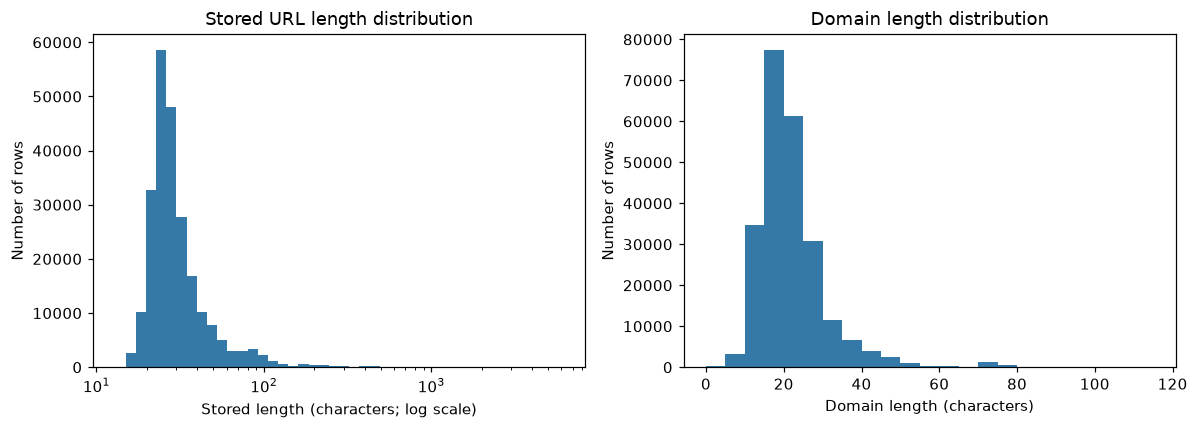

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature, title in zip(axes, ["URLLength", "DomainLength"],
                             ["Stored URL length distribution", "Domain length distribution"]):
    values = df[feature].to_numpy()
    if feature == "URLLength":
        ax.hist(values, bins=np.geomspace(values.min(), values.max() + 1, 45), color="#3579a8")
        ax.set_xscale("log")
        ax.set_xlabel("Stored length (characters; log scale)")
    else:
        ax.hist(values, bins=np.arange(0, 116, 5), color="#3579a8")
        ax.set_xlabel("Domain length (characters)")
    ax.set(title=title, ylabel="Number of rows")
fig.tight_layout()
plt.show()

URL length has a strong right tail: the median is **27**, the middle half spans **23–34**, and the maximum is **6,097**. The log x-axis has unequal character-width bins; the bars show counts per bin, not density per character. Domain length is less spread out, with a median of **20**, an interquartile range of **16–24**, and a maximum of **110**. The URL-length plot uses the stored feature despite its flagged text-length offsets.

NoOfSubDomain,len
i64,u32
0,13983
1,178406
2,36353
3,5119
4,1563
5,336
6,21
7,5
8,4


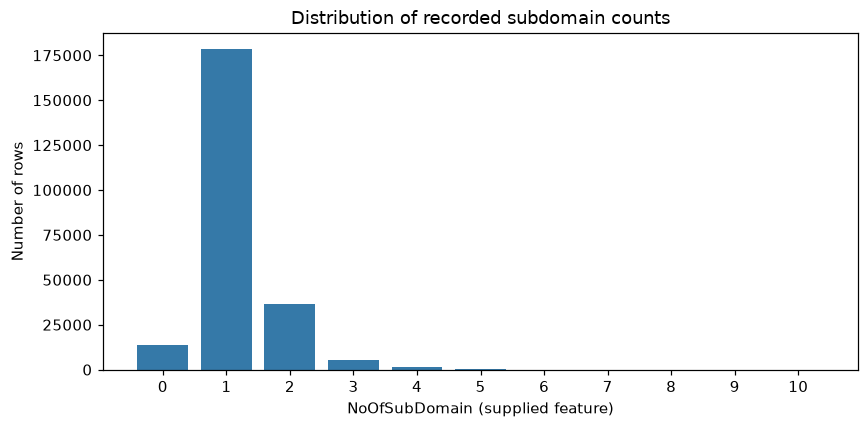

In [9]:
subdomain_counts = df.group_by("NoOfSubDomain").len().sort("NoOfSubDomain")
display(subdomain_counts)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(subdomain_counts["NoOfSubDomain"].to_numpy(), subdomain_counts["len"].to_numpy(), color="#3579a8")
ax.set(title="Distribution of recorded subdomain counts", xlabel="NoOfSubDomain (supplied feature)", ylabel="Number of rows")
ax.set_xticks(range(11))
fig.tight_layout()
plt.show()

One recorded subdomain is the most common value: **178,406 rows (75.7%)**. The median and both quartiles are 1, but the tail reaches 10. The dataset's counting convention is retained; no new subdomain count is inferred from dots, since multi-part domain suffixes can make that misleading.

feature,present_rows,present_pct
str,i64,f64
"""IsHTTPS""",184539,78.262474
"""HasObfuscation""",485,0.205687
"""IsDomainIP""",638,0.270574
"""NoOfURLRedirect""",31464,13.343794
"""HasPasswordField""",24113,10.226256
"""HasExternalFormSubmit""",10372,4.398736


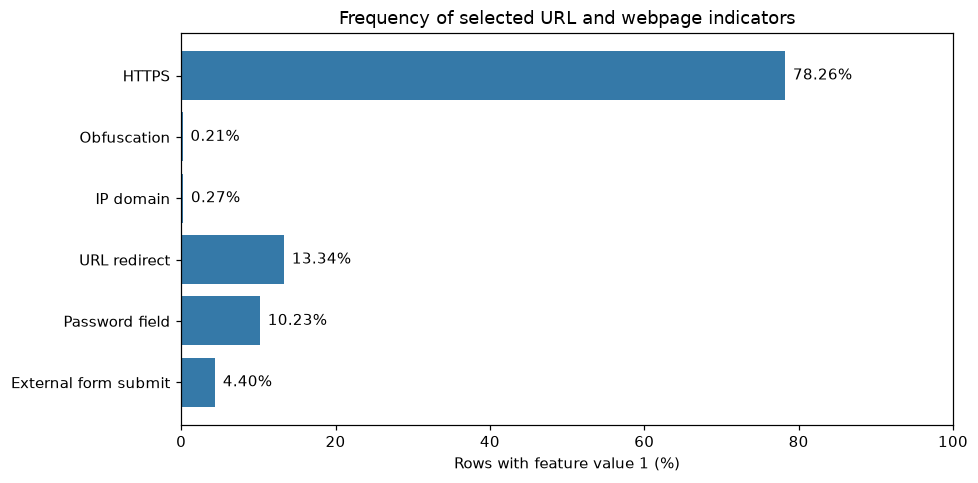

In [10]:
binary_features = ["IsHTTPS", "HasObfuscation", "IsDomainIP", "NoOfURLRedirect", "HasPasswordField", "HasExternalFormSubmit"]
binary_labels = ["HTTPS", "Obfuscation", "IP domain", "URL redirect", "Password field", "External form submit"]
binary_summary = df.select([pl.col(c).sum().alias(c) for c in binary_features]).transpose(
    include_header=True, header_name="feature", column_names=["present_rows"]
).with_columns((100 * pl.col("present_rows") / df.height).alias("present_pct"))
display(binary_summary)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(binary_labels[::-1], binary_summary["present_pct"].to_numpy()[::-1], color="#3579a8")
for i, pct in enumerate(binary_summary["present_pct"].to_numpy()[::-1]):
    ax.text(pct + 1, i, f"{pct:.2f}%", va="center")
ax.set(title="Frequency of selected URL and webpage indicators", xlabel="Rows with feature value 1 (%)", xlim=(0, 100))
fig.tight_layout()
plt.show()

HTTPS is common (**78.26%**), while obfuscation (**0.21%**) and IP-based domains (**0.27%**) are rare. Password fields appear in **10.23%** of rows and external form submission in **4.40%**. These indicators are mostly zero except HTTPS. `NoOfURLRedirect` takes only 0 and 1 in this file (**13.34%** are 1), so it is plotted as an indicator rather than as a broad count distribution.

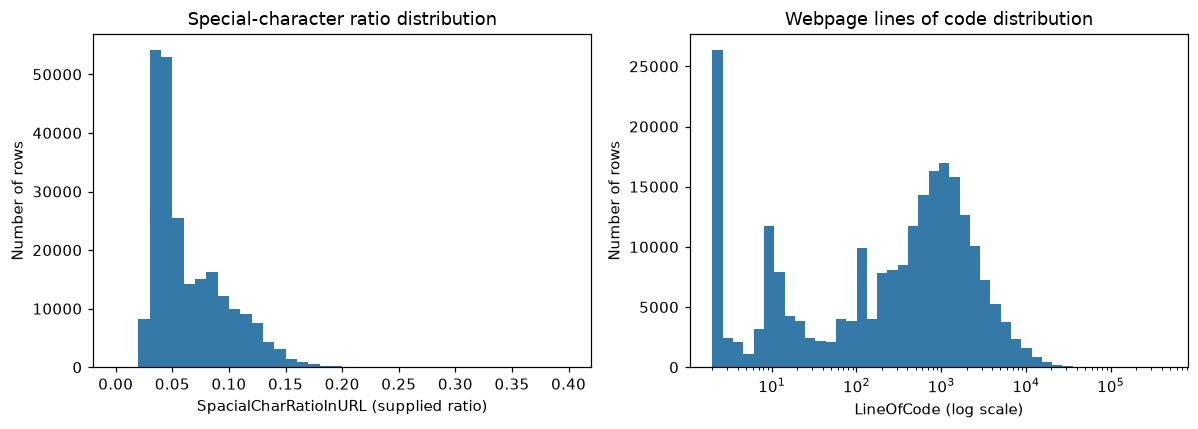

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["SpacialCharRatioInURL"].to_numpy(), bins=np.linspace(0, 0.4, 41), color="#3579a8")
axes[0].set(title="Special-character ratio distribution", xlabel="SpacialCharRatioInURL (supplied ratio)", ylabel="Number of rows")
values = df["LineOfCode"].to_numpy()
axes[1].hist(values, bins=np.geomspace(values.min(), values.max() + 1, 45), color="#3579a8")
axes[1].set_xscale("log")
axes[1].set(title="Webpage lines of code distribution", xlabel="LineOfCode (log scale)", ylabel="Number of rows")
fig.tight_layout()
plt.show()

The special-character ratio centers around **0.05**, with the middle half between **0.038 and 0.083** and a tail up to **0.397**. Lines of code are much more spread out: the median is **429**, the interquartile range is **18–1,277**, and the maximum is **442,666**. The page-size histogram has a large spike at very low values and a broad concentration in the hundreds to thousands. The log scale includes the whole range, with counts per unequal-width bin. Neither special characters nor page size alone establishes phishing.

## D. Feature relationships

All class percentages below use the class's full row count as the denominator (100,945 phishing and 134,850 legitimate). They describe how common a feature is **within a class**, not the probability that a website is phishing given that feature.

feature,label,rows,mean,q25,median,q75,max
str,i64,u32,f64,f64,f64,f64,f64
"""DomainLength""",0,100945,24.465144,16.0,22.0,29.0,110.0
"""DomainLength""",1,134850,19.22861,16.0,19.0,22.0,50.0
"""LineOfCode""",0,100945,65.730467,2.0,12.0,90.0,29687.0
"""LineOfCode""",1,134850,1947.49168,613.0,1105.0,2088.0,442666.0
"""NoOfSubDomain""",0,100945,1.168894,1.0,1.0,1.0,10.0
"""NoOfSubDomain""",1,134850,1.161661,1.0,1.0,1.0,4.0
"""SpacialCharRatioInURL""",0,100945,0.083285,0.051,0.08,0.111,0.397
"""SpacialCharRatioInURL""",1,134850,0.048356,0.036,0.042,0.053,0.231
"""URLLength""",0,100945,45.720293,26.0,34.0,48.0,6097.0


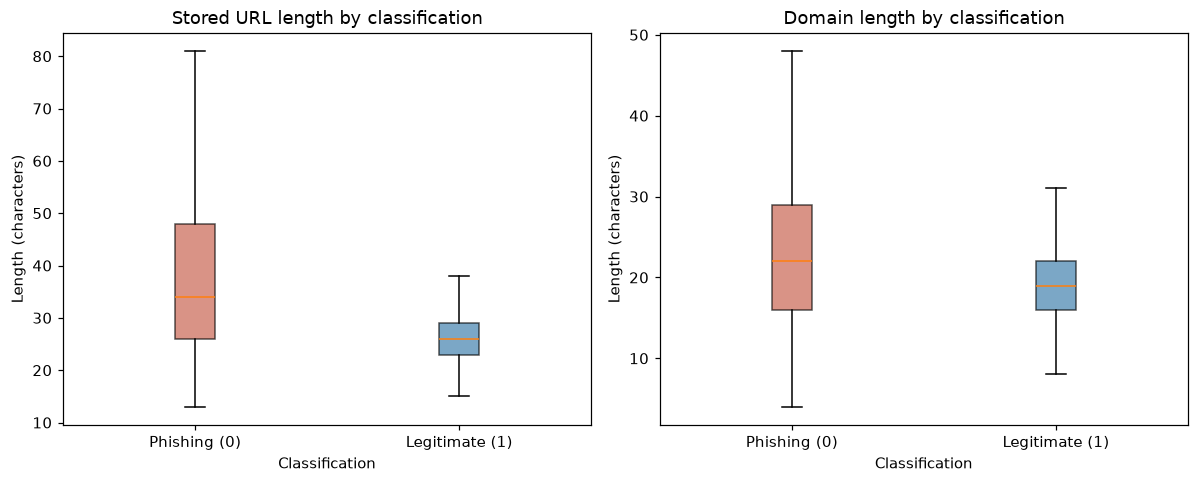

In [12]:
class_stats = []
for c in selected_numeric:
    class_stats.append(df.group_by("label").agg(
        pl.len().alias("rows"), pl.col(c).mean().alias("mean"),
        pl.col(c).quantile(0.25).alias("q25"), pl.col(c).median().alias("median"),
        pl.col(c).quantile(0.75).alias("q75"), pl.col(c).max().alias("max")
    ).with_columns(pl.lit(c).alias("feature")).select("feature", "label", "rows", "mean", "q25", "median", "q75", "max"))
display(pl.concat(class_stats, how="vertical_relaxed").sort("feature", "label"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, feature, title in zip(axes, ["URLLength", "DomainLength"],
                             ["Stored URL length by classification", "Domain length by classification"]):
    groups = [df.filter(pl.col("label") == label)[feature].to_numpy() for label in [0, 1]]
    boxes = ax.boxplot(groups, tick_labels=class_names, showfliers=False, patch_artist=True)
    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    ax.set(title=title, xlabel="Classification", ylabel="Length (characters)")
fig.tight_layout()
plt.show()

### Relationship 1: URL and domain lengths by classification

**So what?** Phishing URLs have a median stored length of **34** (middle half **26–48**), compared with **26** (**23–29**) for legitimate URLs. Domain medians are **22 versus 19**, with middle halves of **16–29 versus 16–22**. Longer, more variable phishing URLs fit the expected pattern, but the overlapping boxes show that short URLs are not enough to identify legitimacy. Outlier markers are hidden for readability; no rows were removed, and the tables and Section C show the full ranges. This agrees with the teammate's existing URL-length observation and adds the domain comparison.

**What next?** Compare URL length within domain-length ranges to see whether the difference mainly comes from the hostname or additional paths and query strings. Use computed text lengths as a sensitivity check before defining any cutoffs.

label,subdomain_group,len,class_rows,percent
i64,str,u32,u32,f64
0,"""0""",13983,100945,13.852098
0,"""1""",63545,100945,62.950121
0,"""2""",18115,100945,17.945416
0,"""3+""",5302,100945,5.252365
1,"""1""",114861,134850,85.176863
1,"""2""",18238,134850,13.524657
1,"""3+""",1751,134850,1.29848


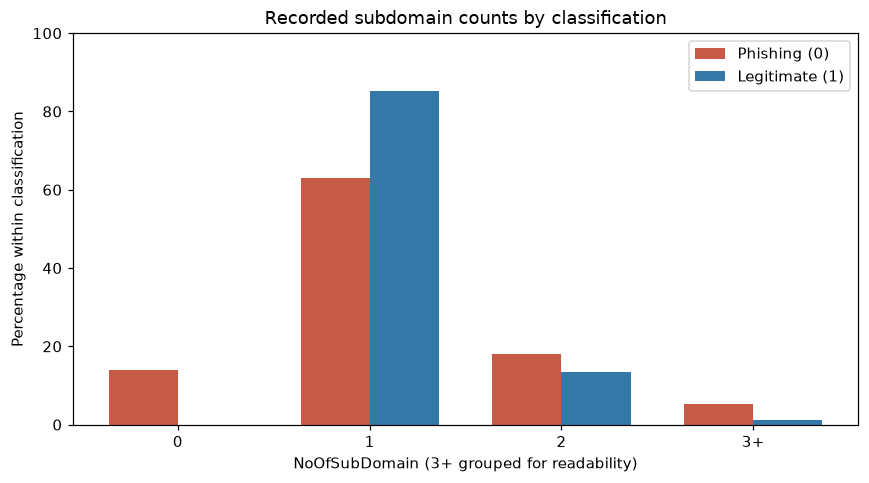

In [13]:
subdomains = df.with_columns(
    pl.when(pl.col("NoOfSubDomain") >= 3).then(pl.lit("3+"))
    .otherwise(pl.col("NoOfSubDomain").cast(pl.String)).alias("subdomain_group")
)
subdomain_rates = subdomains.group_by("label", "subdomain_group").len().join(
    class_counts.select("label", pl.col("len").alias("class_rows")), on="label"
).with_columns((100 * pl.col("len") / pl.col("class_rows")).alias("percent")).sort("label", "subdomain_group")
display(subdomain_rates)
fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ["0", "1", "2", "3+"]
x = np.arange(len(categories))
for label, name, color, offset in zip([0, 1], class_names, colors, [-0.18, 0.18]):
    rates = subdomain_rates.filter(pl.col("label") == label)
    values = [rates.filter(pl.col("subdomain_group") == category)["percent"].item()
              if rates.filter(pl.col("subdomain_group") == category).height else 0 for category in categories]
    ax.bar(x + offset, values, width=0.36, label=name, color=color)
ax.set_xticks(x, categories)
ax.set(title="Recorded subdomain counts by classification", xlabel="NoOfSubDomain (3+ grouped for readability)", ylabel="Percentage within classification", ylim=(0, 100))
ax.legend()
fig.tight_layout()
plt.show()

### Relationship 2: Recorded subdomain counts by classification

**So what?** Both classes are concentrated at one subdomain, but the percentages differ: **63.0%** of phishing rows and **85.2%** of legitimate rows. Three or more occur in **5.3% versus 1.3%**. Surprisingly, all **13,983** zero-subdomain rows are phishing in this sample, while mean counts are almost equal (**1.169 versus 1.162**). Looking only at the mean would miss these differences. The patterns could reflect collection or extraction conventions; they do not show which domain structures confuse people.

**What next?** Inspect examples and confirm the source's subdomain counting rule, especially for zero-count rows. Then compare these groups within HTTPS and domain-length categories.

label,class_rows,IsHTTPS,HasObfuscation,IsDomainIP,NoOfURLRedirect,HasPasswordField,HasExternalFormSubmit
i64,u32,f64,f64,f64,f64,f64,f64
0,100945,49.223835,0.48046,0.632027,15.169647,5.387092,0.426965
1,134850,100.0,0.0,0.0,11.977011,13.848721,7.371895


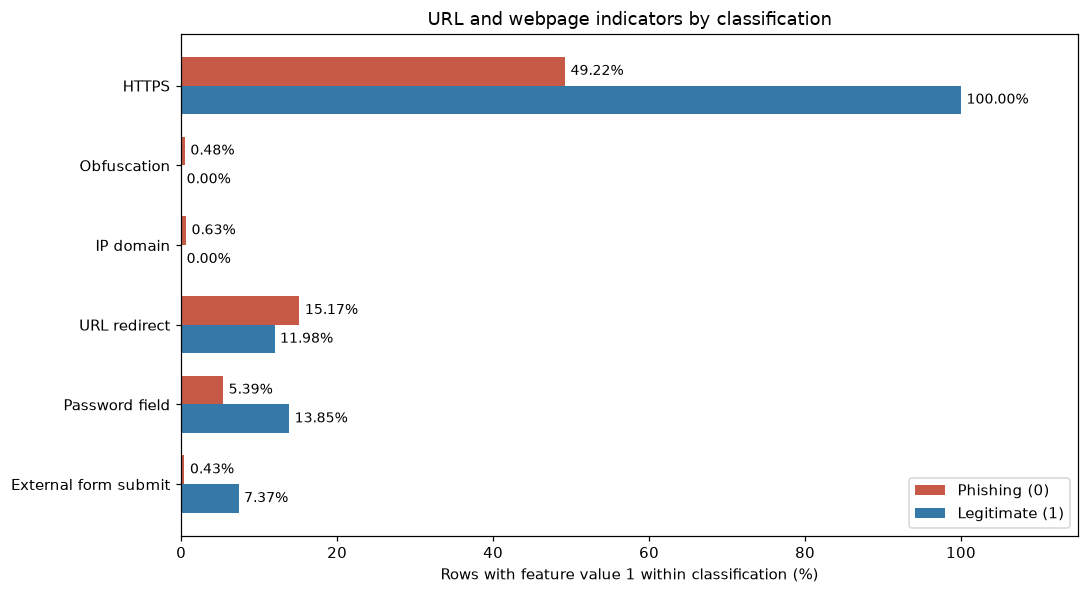

In [14]:
class_binary = df.group_by("label").agg(
    pl.len().alias("class_rows"), *[(100 * pl.col(c).mean()).alias(c) for c in binary_features]
).sort("label")
display(class_binary)
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(binary_features))
for label, name, color, offset in zip([0, 1], class_names, colors, [-0.18, 0.18]):
    values = class_binary.filter(pl.col("label") == label).select(binary_features).row(0)
    bars = ax.barh(y + offset, values, height=0.36, label=name, color=color)
    for bar, value in zip(bars, values):
        ax.text(value + 0.7, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center", fontsize=9)
ax.set_yticks(y, binary_labels)
ax.invert_yaxis()
ax.set(title="URL and webpage indicators by classification", xlabel="Rows with feature value 1 within classification (%)", xlim=(0, 115))
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Relationship 3: URL and webpage indicators by classification

**So what?** HTTPS occurs in **49.22% of phishing rows and 100% of legitimate rows**. It separates groups here, but nearly half of phishing rows also have it, so HTTPS alone is not a reliable legitimacy signal. Obfuscation (**0.48%**) and IP domains (**0.63%**) occur only in phishing rows, but their rarity means they describe very few phishing examples. Unexpectedly, password fields (**5.39% versus 13.85%**) and external form submission (**0.43% versus 7.37%**) are more common among legitimate rows. Legitimate sites also use forms; these features should not be treated as automatic warning signs. Recorded redirects occur in **15.17% versus 11.98%**, a smaller difference; their 0/1 encoding does not measure redirect-chain length.

**What next?** Examine form features among HTTPS-only rows and within webpage-size groups. The table above shows a page-size median of **12 lines for phishing versus 1,105 for legitimate**, so extraction or collection differences may contribute to the form patterns. Any class activity should test whether visible HTTPS cues affect recognition while controlling the other features; participants cannot necessarily see source-code features directly.

## E. Research question reflection

**Original question:** Which features of phishing links and webpages make them harder for people to recognize?

The dataset supports a narrower technical question: **Which URL and webpage characteristics differ between phishing and legitimate rows in PhiUSIIL, especially when phishing rows also have HTTPS or ordinary-looking domain structures?**

The exploratory results suggest useful examples to investigate, rather than an answer about human recognition. Many phishing rows have HTTPS, a single recorded subdomain, and URL lengths overlapping legitimate rows. Meanwhile, forms appear more often in legitimate rows here. These patterns make combinations and context worth studying. They do not prove that any feature causes people to be fooled.

For the proposed class activity, the group could compare recognition accuracy for phishing examples with and without visible HTTPS or different URL structures, using otherwise comparable examples. Webpage appearance would need screenshots or a separate controlled setup because this CSV contains extracted characteristics, not what participants saw. No recognition scores or participant responses are present in this dataset.

Follow-up work should verify feature extraction conventions, check combinations within HTTPS and page-size subgroups, and later see whether patterns hold in the teammates' datasets. This notebook does not join datasets, train models, or produce the unified group report. The repeated URLs, feature inconsistencies, and different collection sources limit how far these findings can be generalized.